In [1]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
import pandas as pd
import seaborn as sns
import math
from scipy.stats import exponnorm
import scipy.special as sse
from scipy.optimize import curve_fit
from scipy import stats
#from pomegranate import *
from sklearn.metrics import mean_squared_error
from sklearn.mixture import GaussianMixture
from scipy.stats import norm
from scipy.special import rel_entr
from sklearn.neighbors import KernelDensity
import scipy.optimize as opt
import scipy.stats as st

In [3]:
file_location = os.path.join('C:\\Users\\Austin\\Desktop\\cell_model\\fig_data', '*imt*')
filenames = glob.glob(file_location)
c1 = "tab:blue"
c2 = "tab:red"

In [11]:
IMTs = []
for f in filenames:
    tmp_df = pd.read_csv(f)
    tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    IMTs.append(tmp_df)

ii=0
for df in IMTs:
    df["IMT"] = df["Division"] - df["Mitotic Frame"]
    df["G1"] = df["Green On"] - df["Mitotic Frame"]
    df["S-M"] = df["Division"] - df["Green On"]
    if ii == 2 or ii == 3 or ii == 6 or ii == 7:
        df["IMT_t"] = df["IMT"] * (32/60)
        df["G1_t"] = df["G1"] * (32/60)
        df["S-M_t"] = df["S-M"] * (32/60)
    else:
        df["IMT_t"] = df["IMT"] * (20/60)
        df["G1_t"] = df["G1"] * (20/60)
        df["S-M_t"] = df["S-M"] * (20/60)
    #df = df[(df["IMT_t"] ==27)].reset_index(drop=True)
    ii+=1
    
stiffs = [0.2, 0.2, 0.6, 0.6, 4, 4, 55, 55]
ii=0
for df in IMTs:
    tmp_stiff = np.ones(len(df))*stiffs[ii]
    df.insert(0, "Stiffness", tmp_stiff)
    if ii % 2 == 0:
        df["Drug"] = "DMSO"
    else:
        df["Drug"] = "ERL"    
    ii+=1

all_IMTs = pd.concat(IMTs, ignore_index=True, sort=False)
centers = np.arange(0.5, 100.5, 1)

In [273]:
from math import log10, floor
def round_sig(x, sig=2):
   return round(x, sig-int(floor(log10(abs(x))))-1)

In [4]:
def emg_fit_func(x, l, s, m):
    return 0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s)) # exponential gaussian

In [5]:
def emg_fit_func_2(x, l, s, m, l_2, s_2, m_2, w):
    return w*(0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s))) + (1-w)*(0.5*l_2*np.exp(0.5*l_2*(2*m_2+l_2*s_2*s_2-2*x))*sse.erfc((m_2+l_2*s_2*s_2-x)/(np.sqrt(2)*s_2))) # exponential gaussian

In [6]:
def logl_emgv2(log_par, data):
    l,s,m = np.exp(log_par)
    eps = 10e-12
    return np.log(list(emg_fit_func(data, l, s, m)+eps)).sum()

In [7]:
def logl_emg2v2(log_par, data):
    l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
    eps = 10e-12
    return np.log(list(emg_fit_func_2(data, l , s, m, l_2, s_2, m_2, w)+eps)).sum()

In [8]:
def calculate_aic(LL, num_params):
    aic = 2*num_params - 2*LL
    return aic

In [214]:
def calc_aics_gmm_emg(data):
    x = np.array(data)
    x = x[~np.isnan(x)]
    x_res = x.reshape(-1,1)

    # Fit models with 1-10 components
    k_arr = np.arange(2) + 1
    models = [GaussianMixture(n_components=k).fit(x_res) for k in k_arr]
    # Compute metrics to determine best hyperparameter
    AIC = [m.aic(x_res) for m in models]
    
    
    params = exponnorm.fit(x)
    exp_c = 1/(params[0]*params[2])
    LLH = exponnorm.logpdf(x,*params).sum()
    emg_aic = calculate_aic(LLH, 3)
    
    AIC.append(emg_aic)
        
    return AIC

In [127]:
def calc_aicc(AIC, num_params, samp_size):
    aicc = AIC + (2*num_params*(num_params+1)/(samp_size-num_params-1))
    return aicc

In [271]:
def calc_aicp(AICs):
    aicp = [math.exp((min(AICs)-AIC)/2) for AIC in AICs]
    return aicp

In [9]:
def emg_mle_v2(data, log_par, bnds):
    res = opt.minimize(
    fun=lambda log_params, data: -logl_emgv2(log_params, data),
    x0=np.array(log_par), args=(data,), bounds=bnds, method='L-BFGS-B')
    log_p = res.x
    params = [np.exp(y) for y in log_p]
    
    return log_p, params

In [10]:
def emg2_mle_v2(data, log_par2, bnds):
    res = opt.minimize(
    fun=lambda log_params, data: -logl_emg2v2(log_params, data),
    x0=np.array(log_par2), args=(data,), bounds=bnds, method='L-BFGS-B')
    log_p = res.x
    params = [np.exp(y) for y in log_p]
    
    return log_p, params

In [256]:
def plot_mixture(gmm, X, show_legend=True, ax=None):
    if ax is None:
        ax = plt.gca()

 # Compute PDF of whole mixture
    x = np.arange(0.5, 100.5, 1)
    logprob = gmm.score_samples(x.reshape(-1, 1))
    pdf = np.exp(logprob)

 # Compute PDF for each component
    responsibilities = gmm.predict_proba(x.reshape(-1, 1))
    pdf_individual = responsibilities * pdf[:, np.newaxis]
    
    
 # Plot data histogram
    ax.hist(X, bins=range(0,101), density=True, histtype='stepfilled', alpha=0.3, label='Data', color='gray')

 # Plot PDF of whole model
    ax.plot(x, pdf, color=c2, label='Mixture PDF')

 # Plot PDF of each component
    ax.plot(x, pdf_individual, '--', color=c2, label='Component PDF')
    ax.set_xlabel('$x$')
    ax.set_ylabel('$p(x)$')
    if show_legend:
        ax.legend()

In [380]:
data = np.array(IMTs[0]["G1_t"])
data = data[~np.isnan(data)]

In [381]:
AICs = calc_aics_gmm_emg(data)

C:\Users\Austin\anaconda3\envs\stoch_cell\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [367]:
AICs

[1061.7301654869957, 1007.2096022351427, 999.058120520345]

In [382]:
emg_init = [0.07, 2, 9.5, 0.07, 2, 35, 0.5]
emg_bounds = [[0, 0, 0, 0, 0, 0, 0], [2, 20, 30, 2, 100, 100, 1]]
h, edges =np.histogram(data, bins=range(0,101), density=True)
popt2,pcov2=(curve_fit(emg_fit_func_2, centers, h, p0=emg_init, bounds=emg_bounds, maxfev=5000))
fitted_curve=list(emg_fit_func_2(centers,*popt2))
log_par2 = [math.log(x) for x in popt2 ]

In [383]:
popt2

array([0.37532123, 1.47204273, 8.78098738, 0.07282424, 2.16373958,
       5.81084739, 0.3812548 ])

In [387]:
log_par2 = [math.log(x) for x in  [0.37532123, 1.47204273, 8.78098738, 0.07282424, 2.16373958,
       5.81084739, 0.9 ]]

In [388]:
bounds = ((-5, 5),
         (-5, 8),
         (-5, 8),
         (-5, 5),
         (-5, 8),
         (-5, 8),
         (-10, -0.00000001))

[log_p2, params2] = emg2_mle_v2(data, log_par2, bounds)

In [389]:
params2

[0.22655873265929757,
 1.4896879773438771,
 8.028495834416022,
 0.04698359437755721,
 1.1249845601887984,
 4.10222324850444,
 0.6084706627117142]

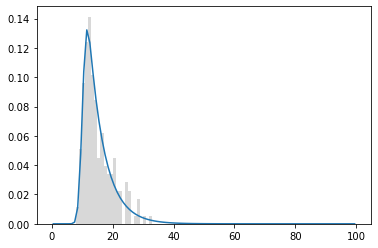

In [373]:
params = exponnorm.fit(data)
y=exponnorm.pdf(centers, *params)
plt.plot(centers,y)
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = plt.stairs(h, edges, fill=True, color='gray', alpha=0.3)

In [218]:
AIC

1967.4440412586782

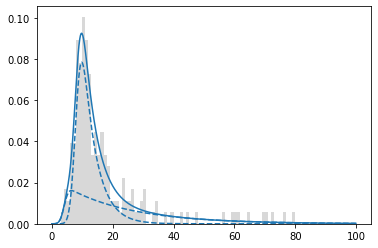

In [390]:
x = np.arange(0,100,0.1)
y = emg_fit_func_2(x,*params2)
y1 = emg_fit_func(x, params2[0], params2[1], params2[2])*params2[6]
y2 = emg_fit_func(x, params2[3], params2[4], params2[5])*(1-params2[6])
plt.plot(x,y, color=c1)
plt.plot(x,y1, color=c1, linestyle='dashed')
plt.plot(x,y2, color=c1, linestyle='dashed')
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = plt.stairs(h, edges, fill=True, color='gray', alpha=0.3)

LL2 = logl_emg2v2(log_p2, data)
AIC2 = calculate_aic(LL2, 7)
AICc2 = calc_aicc(AIC2, 7, len(data))

In [376]:
AICs.append(AICc2)
AICs

[1061.7301654869957, 1007.2096022351427, 999.058120520345, 1007.7208449556566]

(-5.0, 100.0)

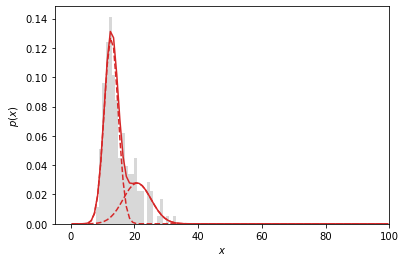

In [379]:
x = data.reshape(-1,1)
model = GaussianMixture(n_components=2).fit(x)
plot_mixture(model, x, show_legend=False)
plt.xlim(xmax=100)

In [377]:
AICp=calc_aicp(AICs)
AICp_r = [round_sig(AICp[0], 3), round_sig(AICp[1], 3), round_sig(AICp[2], 3), round_sig(AICp[3], 3)]
AICp_r

[2.46e-14, 0.017, 1.0, 0.0131]

In [375]:
AICp=calc_aicp(AICs)
AICp_r = [round_sig(AICp[0], 3), round_sig(AICp[1], 3), round_sig(AICp[2], 3)]
AICp_r

[2.46e-14, 0.017, 1.0]